In [1]:
import os
from operator import index

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from dulwich import index
from prophet import plot
from transformers.models.superglue import image_processing_superglue
from xgboost import sklearn

os.chdir(path=r"C:\Users\affan\OneDrive\Desktop\Projects\Insurance_prediction\dataset\imputed_dataset")

insu_df = pd.read_csv(r"imputed.csv")



'ID_policy', 'ID_insured', 'period', 'year_effect_insured',
       'year_lapse_insured', 'year_effect_policy', 'year_lapse_policy',
       'exposure_time', 'lapse', 'seniority_insured', 'seniority_policy',
       'age', 'premium', 'cost_claims_year', 'n_medical_services',
       'n_insured_pc', 'n_insured_mun', 'n_insured_prov', 'IICIMUN',
       'IICIPROV', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P',
       'C_GE_S', 'C_GE_T'

these are the values I got for numerical values

i have choosen

'seniority_insured', 'seniority_policy',
       'age', 'premium', 'cost_claims_year', 'n_medical_services',
       'n_insured_pc', 'n_insured_mun', 'n_insured_prov', 'IICIMUN',
       'IICIPROV', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P',
       'C_GE_S', 'C_GE_T'

as they have much more contribution towards the result



In [111]:

#using pca for feature engineering
insu_colo = insu_df.columns

insu_dtyp = insu_df.dtypes


#insu_num_type = insu_df[insu_dtyp.loc[(insu_dtyp[insu_colo] == "int") | (insu_dtyp[insu_colo] == "float")].index]

insu_num_type = ['seniority_insured', 'seniority_policy',
       'age', 'cost_claims_year', 'n_medical_services',
       'n_insured_pc', 'n_insured_mun', 'n_insured_prov', 'IICIMUN',
       'IICIPROV', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P',
       'C_GE_S', 'C_GE_T']


insu_num_type = insu_df[insu_num_type]

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

#we are standardizing the values for PCA
z_scale = StandardScaler()

insu_num_type = z_scale.fit_transform(insu_num_type)

pca = PCA( n_components=6 )

pca_a = pca.fit_transform(insu_num_type)



In [112]:
pca.explained_variance_ratio_

array([0.42330184, 0.15441255, 0.0988024 , 0.07820849, 0.0529994 ,
       0.04172472])

In [113]:
# Cumulative explained variance
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

# Minimum components needed for 95% variance
n_components = np.argmax(
    cumulative_variance >= 0.95
) + 1

print("Optimal n_components:", n_components)
print("Variance retained:",
      cumulative_variance[n_components - 1])

Optimal n_components: 1
Variance retained: 0.4233018439544436


In [116]:
insu_num_type = ['seniority_insured', 'seniority_policy',
       'age', 'cost_claims_year', 'n_medical_services',
       'n_insured_pc', 'n_insured_mun', 'n_insured_prov', 'IICIMUN',
       'IICIPROV', 'C_GI', 'C_II', 'C_IE_P', 'C_IE_S', 'C_IE_T', 'C_GE_P',
       'C_GE_S', 'C_GE_T']

In [117]:
import pandas as pd

loadings = pd.DataFrame(
    pca.components_.T,
    index=insu_num_type,
    columns=[
        f"PC{i+1}"
        for i in range(pca.n_components_)
    ]
)

print(loadings)

                         PC1       PC2       PC3       PC4       PC5       PC6
seniority_insured   0.152954  0.443292  0.143960 -0.273201 -0.225282  0.112420
seniority_policy    0.153871  0.436390  0.112740 -0.270391 -0.197213  0.117947
age                 0.094252  0.296905  0.314779 -0.149214 -0.336871 -0.047483
cost_claims_year    0.021246  0.100313  0.484836  0.482509  0.174822 -0.022005
n_medical_services  0.035533  0.156045  0.512582  0.403044  0.168733  0.019544
n_insured_pc        0.226441  0.269735 -0.234655  0.086132  0.313836 -0.258008
n_insured_mun       0.230485  0.305885 -0.202387 -0.010739  0.369575 -0.260770
n_insured_prov      0.173121  0.298237 -0.241207  0.039255  0.417762  0.425334
IICIMUN             0.131889  0.149964 -0.316352  0.428880 -0.378164 -0.273126
IICIPROV            0.127422  0.074520 -0.303138  0.480592 -0.402015  0.374240
C_GI                0.285219 -0.119766  0.018842 -0.000829  0.034746  0.359202
C_II                0.324476 -0.144389  0.033009 -0.

In [118]:
print("Variance per component:",
      pca.explained_variance_ratio_)

print("Total variance retained:",
      pca.explained_variance_ratio_.sum())

Variance per component: [0.42330184 0.15441255 0.0988024  0.07820849 0.0529994  0.04172472]
Total variance retained: 0.8494493994902509


In [119]:

#these attributes can be helpful in find the relation between different attributes

insu_df["loss_ratio"] = insu_df["cost_claims_year"] / insu_df["premium"].replace(0, np.nan)
insu_df["cost_per_service"] = insu_df["cost_claims_year"] / insu_df["n_medical_services"].replace(0, np.nan)

In [161]:
# build a simple regression model alogn with the linear regression model

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

#preprocessing
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import ExtraTreesRegressor


model = Pipeline(steps=[

    ('imputer', IterativeImputer(
        estimator=ExtraTreesRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ),
        max_iter=10,
        random_state=42,
        initial_strategy="median"
    )),

    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=7)),
    ('premium', LinearRegression())

])

x = insu_df[insu_num_type]

y = insu_df['premium']

model.fit(x,y)

import os

os.chdir(r"C:\Users\affan\OneDrive\Desktop\Projects\Insurance_prediction\dataset\split")


valid_df = pd.read_csv("validate.csv")


premium_prediction = model.predict(valid_df[insu_num_type])


In [162]:
from sklearn.metrics import root_mean_squared_error


RMSE = root_mean_squared_error(valid_df['premium'], premium_prediction)

In [163]:
RMSE

436.32262543673886

In [153]:
premium_prediction

array([1998.80172074, 1640.9560655 , 1398.65078284, ...,  496.76211769,
        331.69810882,  811.85850221], shape=(35595,))

In [164]:
float()

In [168]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "dataset" / "split"

In [170]:
insu_df['premium']

0         1316.030
1         1075.650
2         1329.060
3         2307.240
4         1936.170
            ...   
150333     627.435
150334     522.972
150335     522.972
150336     486.837
150337     600.279
Name: premium, Length: 150338, dtype: float64

In [182]:

# just create me a visual diagram
from sklearn import set_config

set_config(display = "diagram")

In [183]:
# display the pipeline of the whole process
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['seniority_insured','seniority_policy','age',...,'C_GE_P','C_GE_S', 'C_GE_T']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"estimator estimator: estimator object, default=BayesianRidge()The estimator to use at each step of the round-robin imputation.If `sample_posterior=True`, the estimator must support`return_std` in its `predict` method.",ExtraTreesReg...ndom_state=42)
,"initial_strategy initial_strategy: {'mean', 'median', 'most_frequent', 'constant'}, default='mean'Which strategy to use to initialize the missing values. Same as the`strategy` parameter in :class:`~sklearn.impute.SimpleImputer`.",'median'
,"random_state random_state: int, RandomState instance or None, default=NoneThe seed of the pseudo random number generator to use. Randomizesselection of estimator features if `n_nearest_features` is not `None`,the `imputation_order` if `random`, and the sampling from posterior if`sample_posterior=True`. Use an integer for determinism.See :term:`the Glossary <random_state>`.",42
,"missing_values missing_values: int or np.nan, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`should be set to `np.nan`, since `pd.NA` will be converted to `np.nan`.",nan


In [244]:
insu_df[(insu_df['premium'] >= 200) & (insu_df['gender'] == "M")]['age'].quantile(0)

np.float64(0.0)

Implement a clustering algo like K-Mean

Text(0, 0.5, 'inertia(loss)')

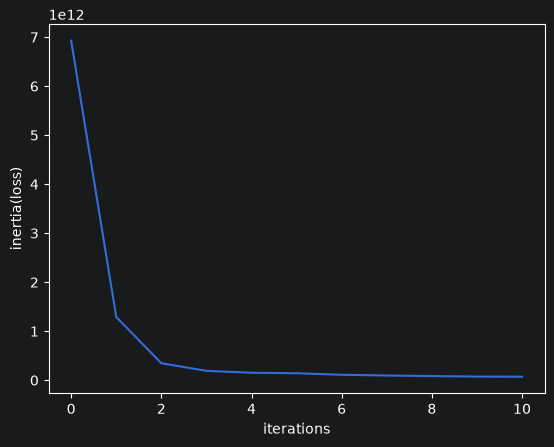

In [310]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

insu_df = pd.read_csv('test.csv')
imput = IterativeImputer(
        estimator=ExtraTreesRegressor(
            n_estimators=1,
            random_state=42,
            n_jobs=-1
        ),
        max_iter=1,
        random_state=42,
        initial_strategy="median"
    )

index = insu_df.index
insu_df = imput.fit_transform(insu_df[insu_num_type])
insu_df = pd.DataFrame(
    insu_df,
    columns=insu_num_type,
    index=index
)


result = []

for i in range(1,12):
    kmean_test = KMeans(n_clusters = i)
    val = kmean_test.fit(insu_df[insu_num_type])
    result.append(val.inertia_)

plt.plot(range(0,11),result)
plt.xlabel("iterations")
plt.ylabel("inertia(loss)")



In [262]:

from sklearn.preprocessing import StandardScaler
from sklearn.impute import IterativeImputer
from sklearn.linear_model import LinearRegression
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.experimental import enable_iterative_imputer

insu_df = pd.read_csv(r'test.csv')

insu_df = insu_df[insu_num_type]

model = Pipeline(steps=[

    ('imputer', IterativeImputer(

        estimator = ExtraTreesRegressor(

            n_estimators=10,
            n_jobs=-1,
            random_state=42,
        ),
        max_iter=10,
        initial_strategy="median"
    )),
    ('scaler', StandardScaler()),
    ('kmean',KMeans(
        n_clusters = 8
    ))
])

model.fit(insu_df[insu_num_type])

check = model.transform(insu_df[insu_num_type])



In [323]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

insu_df = pd.read_csv('test.csv')
imput = IterativeImputer(
        estimator=ExtraTreesRegressor(
            n_estimators=1,
            random_state=42,
            n_jobs=-1
        ),
        max_iter=1,
        random_state=42,
        initial_strategy="median"
    )

index = insu_df.index
insu_df = imput.fit_transform(insu_df[insu_num_type])
insu_df = pd.DataFrame(
    insu_df,
    columns=insu_num_type,
    index=index
)

kmean_test = KMeans(n_clusters = 7)
val = kmean_test.fit(insu_df[insu_num_type])
print(val.cluster_centers_)

[[1.26136012e+01 1.35683374e+01 4.21256348e+01 4.71030458e+02
  1.59229410e+01 1.06047693e+02 2.74054979e+02 2.83656416e+04
  3.72154780e+00 5.12140649e+00 8.39816737e+01 4.70980349e+01
  5.74477810e+01 7.00022080e+01 3.51377788e+01 2.19399426e+01
  4.40028704e+01 7.72936631e+01]
 [6.92108534e+00 7.31255178e+00 3.67456504e+01 4.73119211e+02
  1.16387738e+01 2.62788940e+02 9.22876346e+02 3.27864996e+03
  5.82182063e+00 3.40127589e+00 7.06311102e+01 3.83920878e+01
  5.08247722e+01 6.01041839e+01 4.42999171e+01 1.85188484e+01
  3.39873654e+01 8.32305302e+01]
 [2.35463504e+01 2.55846715e+01 5.37908759e+01 5.96446487e+02
  2.00690998e+01 6.18521168e+02 1.82359805e+04 2.83657038e+04
  1.12185462e+01 5.12074818e+00 9.33212895e+01 6.63233577e+01
  3.93401460e+01 3.01925791e+01 6.88205596e+01 1.36372263e+01
  8.38856448e+00 9.46454988e+01]
 [1.05432007e+01 1.11459759e+01 4.41611471e+01 5.55855825e+02
  1.79925994e+01 1.83411841e+02 3.82244977e+03 7.00115005e+03
  8.48465865e+00 5.22203515e+00 9

In [324]:
insu_df['cluster'] = val.labels_

In [325]:
val.labels_

array([3, 1, 3, ..., 1, 1, 1], shape=(34806,), dtype=int32)

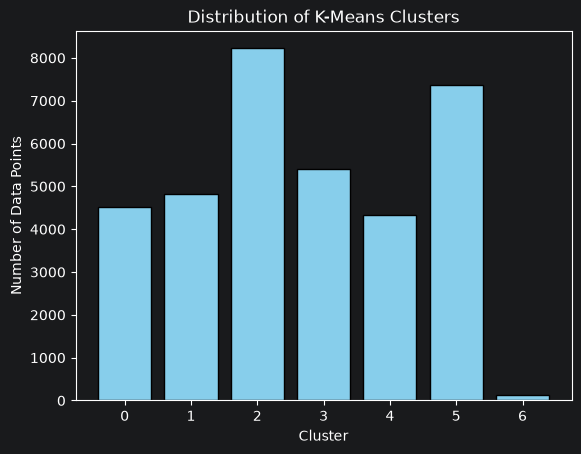

In [350]:

#checking how the values are distributed

se = pd.Series(val.labels_).value_counts().sort_values(ascending=True)


x = list(se.index)
y = list(se)


plt.bar(x, y, color="skyblue", edgecolor="black")

plt.xlabel("Cluster")
plt.ylabel("Number of Data Points")
plt.title("Distribution of K-Means Clusters")
plt.xticks(x)
plt.show()